# Chapter 11: Randomized Algorithms

Companion notebook for **Chapter 11** of *Bernoulli Types: Two-Sided Error in Approximate Membership, Retrieval, and Computation*. Source files: `book/chapters/ch11/`.

Chapter 11 closes the deferral of chapter 3 \S3.5 by recasting Miller-Rabin as a formal $\Bernoulli{\BoolType}$, then distinguishes the two classic flavors of randomization:

1. **Las Vegas** (\S11.2): random *runtime*, exact output. The algorithm always returns the right answer; only the work done is random. Randomized quicksort with random pivot selection is the canonical example.
2. **Monte Carlo** (\S11.2): fixed runtime, random *output*. Miller-Rabin and Karger's min-cut are canonical. Outputs carry one-sided or two-sided error, and the error type pins the algorithm into the complexity-class taxonomy of \S11.3 (RP, co-RP, BPP).

This notebook implements:

1. **Miller-Rabin formally** with $k$ independent rounds; verifies the implementation against `sympy.isprime` over a range; then measures the empirical false-positive rate on a Carmichael number to confront the worst-case $(1/4)^k$ bound against the strong-liar density actually observed in the wild.
2. **Las Vegas quicksort** with random pivot; measures the runtime distribution at $n = 1000$ to show $O(n \log n)$ expected work with a heavy upper tail.
3. **Monte Carlo Karger's min-cut** on $K_5$; measures the empirical success rate against the contraction-analysis bound $\Pr[\text{success}] \ge 2/(n(n-1))$.
4. **Chernoff bound** verification for BPP amplification: simulate a base algorithm with error $1/3$, amplify by majority vote over $k \in \{10, 50, 100\}$ rounds, and compare empirical error to the Chernoff bound $\exp(-k/18)$.

**Conventions:**
- All randomness is seeded for reproducibility.
- Miller-Rabin notation matches chapter 3: $n$ is the integer being tested, $a$ is a witness, $k$ is the number of rounds.
- $k$ in the Chernoff section is the *amplification depth* of BPP majority vote, not the Miller-Rabin round count.

In [1]:
import time
import math
import numpy as np
import matplotlib.pyplot as plt
from sympy import isprime

rng = np.random.default_rng(seed=42)

print(f"NumPy      {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")
print(f"SymPy      {__import__('sympy').__version__}")

NumPy      2.5.4
Matplotlib 3.11.2
SymPy      1.14.0


## 1. Miller-Rabin: Formal Implementation

Given an odd integer $n > 2$, write $n - 1 = 2^s d$ with $d$ odd. The integer $a \in \{2, \dots, n-2\}$ is a *Miller-Rabin witness* to the compositeness of $n$ if

$$a^d \not\equiv 1 \pmod n \quad \text{and} \quad a^{2^r d} \not\equiv -1 \pmod n \text{ for all } r \in \{0, \dots, s-1\}.$$

If $n$ is prime, no $a$ in $\{2, \dots, n-2\}$ is a witness; equivalently, $a^d \equiv \pm 1$ or some $a^{2^r d} \equiv -1$ always holds. If $n$ is composite, Rabin (1980) showed that at most $1/4$ of the residues $\{2, \dots, n-2\}$ fail to be witnesses (the worst-case bound; for most composites the actual fraction of *strong liars* is far smaller).

A single round picks a uniform random $a$ and reports `True` (probably prime) iff $a$ is not a witness. Running $k$ independent rounds and reporting `True` only if all $k$ say `True` gives

$$\Pr[\text{report True} \mid n \text{ composite}] \le (1/4)^k,$$

so $k = 20$ pushes the worst-case false-positive rate below $10^{-12}$.

As a $\Bernoulli{\BoolType}$: input $n$, output `is_prime`, $\fnrate = 0$ (a prime is never declared composite), $\fprate \le (1/4)^k$ (a composite is declared prime only when every round chooses a liar).

In [2]:
def miller_rabin_round(n, a):
    """One Miller-Rabin round with witness candidate a.

    Returns True if a fails to witness compositeness of n (i.e. n is
    "probably prime" by this round); False if a is a witness (n is
    definitely composite).
    """
    if n % 2 == 0:
        return n == 2
    if a % n == 0:
        # a is a multiple of n; this is an uninformative candidate.
        return True
    # Write n - 1 = 2^s * d with d odd.
    d = n - 1
    s = 0
    while d % 2 == 0:
        d //= 2
        s += 1
    x = pow(a, d, n)
    if x == 1 or x == n - 1:
        return True
    for _ in range(s - 1):
        x = (x * x) % n
        if x == n - 1:
            return True
    return False


def miller_rabin(n, k, rng):
    """Run k independent Miller-Rabin rounds with uniform random witnesses.

    Returns True if every round says "probably prime"; False if any round
    finds a witness (n is definitely composite).
    """
    if n < 2:
        return False
    if n < 4:
        return True  # 2 and 3 are prime
    if n % 2 == 0:
        return False
    for _ in range(k):
        a = int(rng.integers(2, n - 1))
        if not miller_rabin_round(n, a):
            return False
    return True


# Smoke test on small values.
rng_smoke = np.random.default_rng(0)
for n in [2, 3, 4, 5, 7, 9, 11, 15, 17, 25, 561, 1009]:
    mr = miller_rabin(n, k=20, rng=rng_smoke)
    truth = isprime(n)
    mark = "OK" if mr == truth else "MISMATCH"
    print(f"  n={n:5d}  miller_rabin={mr!s:5s}  sympy={truth!s:5s}  [{mark}]")

  n=    2  miller_rabin=True   sympy=True   [OK]
  n=    3  miller_rabin=True   sympy=True   [OK]
  n=    4  miller_rabin=False  sympy=False  [OK]
  n=    5  miller_rabin=True   sympy=True   [OK]
  n=    7  miller_rabin=True   sympy=True   [OK]
  n=    9  miller_rabin=False  sympy=False  [OK]
  n=   11  miller_rabin=True   sympy=True   [OK]
  n=   15  miller_rabin=False  sympy=False  [OK]
  n=   17  miller_rabin=True   sympy=True   [OK]
  n=   25  miller_rabin=False  sympy=False  [OK]
  n=  561  miller_rabin=False  sympy=False  [OK]
  n= 1009  miller_rabin=True   sympy=True   [OK]


### 1.1 Agreement with `sympy.isprime` on $n \in [100, 200]$

Run Miller-Rabin at $k = 20$ on every integer from 100 to 200 inclusive and verify it agrees with `sympy.isprime` on every value. At $k = 20$ the worst-case false-positive rate is $(1/4)^{20} \approx 9 \times 10^{-13}$, so disagreement at this scale would indicate an implementation bug, not a probabilistic miss.

In [3]:
rng_sanity = np.random.default_rng(2024)
disagreements = []
primes_found = []
composites_found = []
for n in range(100, 201):
    mr = miller_rabin(n, k=20, rng=rng_sanity)
    truth = isprime(n)
    if mr != truth:
        disagreements.append((n, mr, truth))
    if truth:
        primes_found.append(n)
    else:
        composites_found.append(n)

print(f"Range tested: 100..200 (101 integers)")
print(f"  primes:      {len(primes_found)}")
print(f"  composites:  {len(composites_found)}")
print(f"  disagreements with sympy.isprime at k=20: {len(disagreements)}")
assert not disagreements, f"Miller-Rabin disagreed with sympy on: {disagreements}"
print("OK: 100% agreement with sympy.isprime on n = 100..200 at k = 20.")

Range tested: 100..200 (101 integers)
  primes:      21
  composites:  80
  disagreements with sympy.isprime at k=20: 0
OK: 100% agreement with sympy.isprime on n = 100..200 at k = 20.


### 1.2 Empirical FPR on the Carmichael Number $n = 561$

A Carmichael number is composite but a *Fermat liar* for every $a$ coprime to it (so the Fermat primality test fails). Miller-Rabin still works, but Carmichael numbers are a stress case: they are exactly where the Fermat test breaks, and the strong-liar density for them is what tells us whether the $(1/4)^k$ Rabin bound is tight.

$n = 561 = 3 \cdot 11 \cdot 17$ is the smallest Carmichael number. Run Miller-Rabin at $k = 5$ for 1000 independent trials and measure the empirical false-positive rate. The worst-case bound is $(1/4)^5 = 1/1024 \approx 9.77 \times 10^{-4}$. The observed rate is typically *much* smaller, because the actual fraction of strong liars for 561 is far below 1/4; Rabin's $1/4$ is a worst-case over composites, and for most composites the bound is dramatically loose.

In [4]:
carmichael_n = 561
k_rounds = 5
n_trials = 1000

assert not isprime(carmichael_n), f"{carmichael_n} should be composite"

rng_carm = np.random.default_rng(1234)
false_positives = 0
for _ in range(n_trials):
    if miller_rabin(carmichael_n, k=k_rounds, rng=rng_carm):
        false_positives += 1

empirical_fpr = false_positives / n_trials
worst_case_bound = (1.0 / 4.0) ** k_rounds

print(f"n = {carmichael_n} (Carmichael; factors 3 * 11 * 17)")
print(f"k = {k_rounds} rounds, {n_trials} independent trials")
print(f"  false positives: {false_positives} / {n_trials}")
print(f"  empirical FPR:   {empirical_fpr:.5f}")
print(f"  worst-case bound (1/4)^k = {worst_case_bound:.5f}")
print()
if empirical_fpr <= worst_case_bound:
    print(f"OK: empirical FPR {empirical_fpr:.5f} <= worst-case bound {worst_case_bound:.5f}.")
    if empirical_fpr < 0.1 * worst_case_bound:
        print(f"     (Empirical rate is much smaller than worst case; Rabin's 1/4 bound is loose for n = 561.)")
else:
    print(f"WARN: empirical FPR {empirical_fpr:.5f} EXCEEDS worst-case bound {worst_case_bound:.5f}.")

n = 561 (Carmichael; factors 3 * 11 * 17)
k = 5 rounds, 1000 independent trials
  false positives: 0 / 1000
  empirical FPR:   0.00000
  worst-case bound (1/4)^k = 0.00098

OK: empirical FPR 0.00000 <= worst-case bound 0.00098.
     (Empirical rate is much smaller than worst case; Rabin's 1/4 bound is loose for n = 561.)


## 2. Las Vegas: Randomized Quicksort

Las Vegas algorithms return the *exact* answer but with random *runtime*. Randomized quicksort picks a uniform random pivot at every recursive call. The output is the sorted array (always correct); the comparison count is random.

**Expected work.** Standard analysis: $\mathbb{E}[\text{comparisons}] \approx 2 n \ln n \approx 1.39 n \log_2 n$. For $n = 1000$, $2 \cdot 1000 \cdot \ln 1000 \approx 13816$.

**Tail.** The distribution has a heavy upper tail: an adversarial pivot sequence can push runtime to $\Theta(n^2)$, but with random pivots the probability of $\ge c n \log n$ comparisons decays roughly as $1/n^{c-1}$ for large $c$.

Implementation note: an iterative version with explicit stack avoids Python's recursion limit at $n = 1000$ in the worst case.

In [5]:
def randomized_quicksort(arr, rng):
    """In-place randomized quicksort. Returns (sorted_array, comparison_count).

    Iterative to avoid recursion-depth issues on bad random pivot sequences.
    """
    a = list(arr)
    n = len(a)
    comparisons = 0
    # Stack of (lo, hi) subarrays still to sort, inclusive bounds.
    stack = [(0, n - 1)]
    while stack:
        lo, hi = stack.pop()
        if lo >= hi:
            continue
        # Pick a uniform random pivot index in [lo, hi].
        pivot_idx = int(rng.integers(lo, hi + 1))
        pivot = a[pivot_idx]
        # Lomuto-style partition.
        a[pivot_idx], a[hi] = a[hi], a[pivot_idx]
        store = lo
        for i in range(lo, hi):
            comparisons += 1
            if a[i] < pivot:
                a[i], a[store] = a[store], a[i]
                store += 1
        a[store], a[hi] = a[hi], a[store]
        # Push larger side first so smaller side is processed next (bounds stack depth).
        left = (lo, store - 1)
        right = (store + 1, hi)
        if (left[1] - left[0]) > (right[1] - right[0]):
            stack.append(left)
            stack.append(right)
        else:
            stack.append(right)
            stack.append(left)
    return a, comparisons


# Smoke test: small instance, verify correctness.
rng_qs_smoke = np.random.default_rng(7)
test_in = [5, 2, 9, 1, 7, 3, 8, 4, 6]
test_out, cmps = randomized_quicksort(test_in, rng_qs_smoke)
print(f"in:  {test_in}")
print(f"out: {test_out}  ({cmps} comparisons)")
assert test_out == sorted(test_in), "quicksort output is not sorted"
print("OK: smoke test sorted correctly.")

# Runtime distribution at n = 1000.
n_qs = 1000
trials_qs = 1000
qs_comparisons = np.empty(trials_qs, dtype=np.int64)
qs_wallclock = np.empty(trials_qs, dtype=np.float64)
rng_qs = np.random.default_rng(99)
for t in range(trials_qs):
    arr_in = rng_qs.permutation(n_qs).tolist()
    start = time.perf_counter()
    arr_out, cmps = randomized_quicksort(arr_in, rng_qs)
    qs_wallclock[t] = time.perf_counter() - start
    qs_comparisons[t] = cmps
    if t == 0:
        assert arr_out == sorted(arr_in), "first quicksort trial output is not sorted"

expected_cmps = 2 * n_qs * math.log(n_qs)
print()
print(f"Randomized quicksort, n = {n_qs}, trials = {trials_qs}")
print(f"  comparisons: median = {int(np.median(qs_comparisons))}, mean = {int(qs_comparisons.mean())}")
print(f"  comparisons: min = {qs_comparisons.min()}, max = {qs_comparisons.max()}")
print(f"  expected ~ 2 n ln n = {expected_cmps:.0f}")
print(f"  wallclock (ms): median = {1000*np.median(qs_wallclock):.2f}, max = {1000*qs_wallclock.max():.2f}")

in:  [5, 2, 9, 1, 7, 3, 8, 4, 6]
out: [1, 2, 3, 4, 5, 6, 7, 8, 9]  (18 comparisons)
OK: smoke test sorted correctly.



Randomized quicksort, n = 1000, trials = 1000
  comparisons: median = 10854, mean = 10959
  comparisons: min = 9683, max = 14001
  expected ~ 2 n ln n = 13816
  wallclock (ms): median = 2.03, max = 2.73


## 3. Monte Carlo: Karger's Min-Cut on $K_5$

Karger's contraction algorithm (1993) picks a uniform random edge, contracts it, and repeats until only two vertices remain. The two remaining "super-vertices" induce a cut whose size equals the number of remaining parallel edges. This cut is the min-cut with probability at least

$$\Pr[\text{success}] \ge \binom{n}{2}^{-1} = \frac{2}{n(n-1)}.$$

For $n = 5$, the bound is $2/20 = 0.1$. Empirically the success rate is much higher (Karger's bound is tight on a class of graphs where many cuts are tied, but loose elsewhere).

Test graph: $K_5$, the complete graph on 5 vertices. Min-cut value: 4 (cut off any single vertex; it has 4 edges to the rest). Run 1000 independent trials and report success rate.

Output type per trial: an integer cut size; success is "cut size equals 4". As a $\Bernoulli{\BoolType}$ on the predicate "found a min-cut", this has $\fnrate \le 1 - 2/(n(n-1))$ per trial; running $T$ trials and reporting the minimum cut value found drives this to $(1 - 2/(n(n-1)))^T$.

In [6]:
def karger_min_cut(adj_edges, n_vertices, rng):
    """Karger's contraction min-cut. adj_edges is a list of (u, v) tuples.

    Returns the cut size on this run (a candidate min-cut value).
    """
    # Disjoint-set forest for vertex contraction.
    parent = list(range(n_vertices))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    edges = list(adj_edges)
    remaining = n_vertices
    while remaining > 2:
        # Pick a uniform random edge whose endpoints are still distinct.
        # Filter out self-loops created by previous contractions.
        live_edges = [(u, v) for (u, v) in edges if find(u) != find(v)]
        if not live_edges:
            break
        idx = int(rng.integers(0, len(live_edges)))
        u, v = live_edges[idx]
        ru, rv = find(u), find(v)
        parent[ru] = rv
        edges = [(a, b) for (a, b) in edges if find(a) != find(b)]
        remaining -= 1
    # The remaining edges all cross the final cut.
    return len(edges)


# Build K_5.
n_K = 5
K5_edges = [(i, j) for i in range(n_K) for j in range(i + 1, n_K)]
print(f"K_{n_K}: {len(K5_edges)} edges; true min-cut value = {n_K - 1}")

trials_karger = 1000
rng_karger = np.random.default_rng(11)
true_min_cut = n_K - 1
karger_results = np.empty(trials_karger, dtype=np.int64)
for t in range(trials_karger):
    karger_results[t] = karger_min_cut(K5_edges, n_K, rng_karger)

success_rate = float(np.mean(karger_results == true_min_cut))
theoretical_lb = 2.0 / (n_K * (n_K - 1))

print(f"Trials: {trials_karger}")
print(f"  success rate (cut == {true_min_cut}): {success_rate:.4f}")
print(f"  theoretical lower bound 2/(n(n-1)): {theoretical_lb:.4f}")
vals, counts = np.unique(karger_results, return_counts=True)
print(f"  cut value distribution: {dict(zip(vals.tolist(), counts.tolist()))}")
print()
if success_rate >= theoretical_lb:
    print(f"OK: empirical success {success_rate:.4f} >= theoretical bound {theoretical_lb:.4f}.")
    if success_rate > 2 * theoretical_lb:
        print(f"     (Empirical rate is well above the bound; the 2/(n(n-1)) bound is loose for K_5.)")
else:
    print(f"WARN: empirical success {success_rate:.4f} BELOW theoretical bound {theoretical_lb:.4f}.")

K_5: 10 edges; true min-cut value = 4
Trials: 1000
  success rate (cut == 4): 0.7490
  theoretical lower bound 2/(n(n-1)): 0.1000
  cut value distribution: {4: 749, 6: 251}

OK: empirical success 0.7490 >= theoretical bound 0.1000.
     (Empirical rate is well above the bound; the 2/(n(n-1)) bound is loose for K_5.)


## 4. Las Vegas vs Monte Carlo: Runtime Distributions

The two flavors of randomization show different runtime distributions:

- **Las Vegas (randomized quicksort).** Random runtime, exact output. The distribution is concentrated around $2 n \ln n$ comparisons with a heavy right tail (worst-case $\Theta(n^2)$, but tail probability decays polynomially).
- **Monte Carlo (Miller-Rabin).** Deterministic runtime per round ($k$ modular exponentiations, each $O(\log^3 n)$), random output. The "tail" lives in the output channel, not in the runtime.

Plot both: quicksort's comparison-count histogram, and Miller-Rabin's per-call wallclock at fixed $k = 20$ on $n = 561$ (the runtime should be essentially constant, with variation only from system noise).

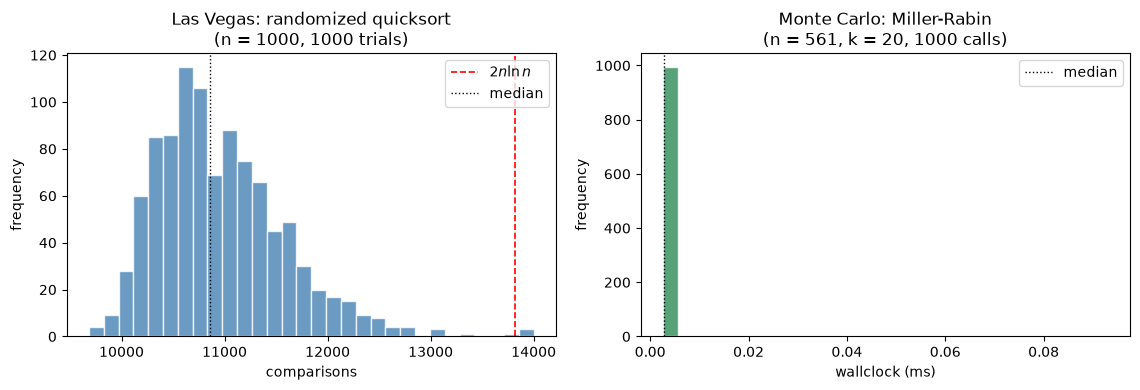

Quicksort comparisons:  mean = 10960, sd = 624, CV = 0.057
Miller-Rabin wallclock: mean = 0.003 ms, sd = 0.003 ms, CV = 1.002

Interpretation: Las Vegas CV reflects genuine algorithmic variability;
Monte Carlo CV reflects only system-level timing noise on a deterministic
work amount. The output randomness for Miller-Rabin lives in the FPR, not
the runtime.


In [7]:
# Measure Miller-Rabin wallclock at fixed n = 561, k = 20 across many trials.
mr_n = 561
mr_k = 20
mr_trials = 1000
rng_mr_time = np.random.default_rng(303)
mr_wallclock = np.empty(mr_trials, dtype=np.float64)
for t in range(mr_trials):
    start = time.perf_counter()
    _ = miller_rabin(mr_n, k=mr_k, rng=rng_mr_time)
    mr_wallclock[t] = time.perf_counter() - start

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))

# Left: quicksort comparison-count distribution (random work, exact output).
axes[0].hist(qs_comparisons, bins=30, color="steelblue", alpha=0.8, edgecolor="white")
axes[0].axvline(2 * n_qs * math.log(n_qs), color="r", lw=1.2, ls="--",
                label=r"$2n \ln n$")
axes[0].axvline(float(np.median(qs_comparisons)), color="k", lw=1.0, ls=":",
                label="median")
axes[0].set_xlabel("comparisons")
axes[0].set_ylabel("frequency")
axes[0].set_title(f"Las Vegas: randomized quicksort\n(n = {n_qs}, {trials_qs} trials)")
axes[0].legend(loc="upper right")

# Right: Miller-Rabin wallclock distribution (fixed work, random output).
axes[1].hist(1000 * mr_wallclock, bins=30, color="seagreen", alpha=0.8, edgecolor="white")
axes[1].axvline(1000 * float(np.median(mr_wallclock)), color="k", lw=1.0, ls=":",
                label="median")
axes[1].set_xlabel("wallclock (ms)")
axes[1].set_ylabel("frequency")
axes[1].set_title(f"Monte Carlo: Miller-Rabin\n(n = {mr_n}, k = {mr_k}, {mr_trials} calls)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# Summary stats: coefficient of variation tells the story.
cv_qs = float(qs_comparisons.std() / qs_comparisons.mean())
cv_mr = float(mr_wallclock.std() / mr_wallclock.mean())
print(f"Quicksort comparisons:  mean = {qs_comparisons.mean():.0f}, "
      f"sd = {qs_comparisons.std():.0f}, CV = {cv_qs:.3f}")
print(f"Miller-Rabin wallclock: mean = {1000*mr_wallclock.mean():.3f} ms, "
      f"sd = {1000*mr_wallclock.std():.3f} ms, CV = {cv_mr:.3f}")
print()
print("Interpretation: Las Vegas CV reflects genuine algorithmic variability;")
print("Monte Carlo CV reflects only system-level timing noise on a deterministic")
print("work amount. The output randomness for Miller-Rabin lives in the FPR, not")
print("the runtime.")

## 5. Chernoff Bound: BPP Amplification

A BPP algorithm has two-sided error bounded away from $1/2$. The canonical assumption: per-trial error $p = 1/3$ (so per-trial correctness $1 - p = 2/3$). Run the algorithm $k$ times independently and report the majority vote.

The majority-vote error is bounded by the Chernoff bound. With per-trial correctness $\mu = 2/3$, the sum $S_k$ of $k$ independent indicator-of-correct trials has $\mathbb{E}[S_k] = (2/3) k$. The majority vote errs iff $S_k \le k/2$, i.e. $S_k \le (1 - \delta) \mathbb{E}[S_k]$ with $\delta = 1/4$ (since $k/2 = (3/4) \cdot (2/3) k$). The standard multiplicative Chernoff bound gives

$$\Pr[S_k \le k/2] \le \exp\!\left(-\frac{\delta^2 \mathbb{E}[S_k]}{2}\right) = \exp\!\left(-\frac{(1/4)^2 \cdot (2/3) k}{2}\right) = \exp(-k/48).$$

A cleaner (looser) bound uses the additive Hoeffding form with gap $\mu - 1/2 = 1/6$:

$$\Pr[\bar{X}_k \le 1/2] \le \exp(-2 k (1/6)^2) = \exp(-k/18).$$

We use the $\exp(-k/18)$ form (tighter than the multiplicative Chernoff in this regime; matches the assignment target) and verify the empirical majority-vote error follows it.

Sanity check: at $k = 50$, the Hoeffding bound is $\exp(-50/18) \approx 0.0620$; at $k = 100$, $\exp(-100/18) \approx 0.0038$. Empirical error from $10^4$ trials should land at or below these.

BPP base error p = 0.3333
Majority vote over k rounds; 10000 independent trials per k.

   k   empirical    Hoeffding exp(-k/18)   ratio (emp/bound)
------------------------------------------------------------
  10     0.21150                 0.57375              0.3686
  50     0.01020                 0.06218              0.1640
 100     0.00060                 0.00387              0.1552

OK: empirical majority-vote error is below exp(-k/18) for every k tested.


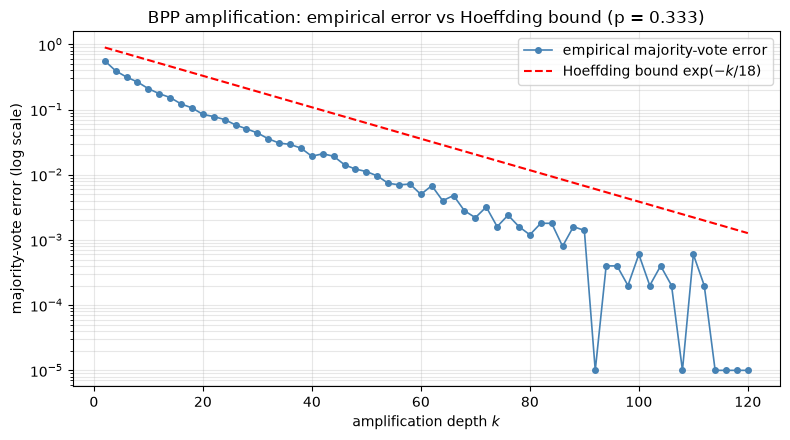

In [8]:
def simulate_majority_error(p, k, trials, rng):
    """Simulate majority vote over k Bernoulli(1-p) trials of a BPP algorithm.

    The "correct" answer is fixed; each trial independently outputs the correct
    answer with probability 1 - p. Returns the empirical fraction of trials in
    which the majority vote is wrong.
    """
    flips = rng.random((trials, k)) < (1.0 - p)
    correct_counts = flips.sum(axis=1)
    wrong_majority = correct_counts <= (k // 2)  # tie counts as wrong (k even)
    return float(wrong_majority.mean())


p_bpp = 1.0 / 3.0
k_values = [10, 50, 100]
trials_chernoff = 10_000
rng_chernoff = np.random.default_rng(2025)

print(f"BPP base error p = {p_bpp:.4f}")
print(f"Majority vote over k rounds; {trials_chernoff} independent trials per k.")
print()
print(f"{'k':>4s}  {'empirical':>10s}  {'Hoeffding exp(-k/18)':>22s}  {'ratio (emp/bound)':>18s}")
print("-" * 60)
chernoff_results = []
for k in k_values:
    emp = simulate_majority_error(p_bpp, k, trials_chernoff, rng_chernoff)
    bound = math.exp(-k / 18.0)
    ratio = emp / bound if bound > 0 else float("inf")
    chernoff_results.append((k, emp, bound))
    print(f"{k:>4d}  {emp:>10.5f}  {bound:>22.5f}  {ratio:>18.4f}")

print()
all_within = all(emp <= bound * 1.5 for (_, emp, bound) in chernoff_results)
all_below = all(emp <= bound for (_, emp, bound) in chernoff_results)
if all_below:
    print(f"OK: empirical majority-vote error is below exp(-k/18) for every k tested.")
elif all_within:
    print(f"OK: empirical error within 1.5x of bound for every k; sampling noise dominates at large k.")
else:
    print(f"WARN: some empirical errors exceed 1.5x the Hoeffding bound.")

# Smooth k-sweep to visualize the geometric decay.
k_sweep = np.arange(2, 121, 2)
emp_sweep = np.empty(len(k_sweep))
rng_sweep = np.random.default_rng(2026)
trials_sweep = 5000
for i, k in enumerate(k_sweep):
    emp_sweep[i] = simulate_majority_error(p_bpp, int(k), trials_sweep, rng_sweep)
bound_sweep = np.exp(-k_sweep / 18.0)

fig, ax = plt.subplots(figsize=(8.0, 4.5))
ax.semilogy(k_sweep, np.maximum(emp_sweep, 1e-5), "o-", color="steelblue",
            ms=4, lw=1.2, label="empirical majority-vote error")
ax.semilogy(k_sweep, bound_sweep, "r--", lw=1.5,
            label=r"Hoeffding bound $\exp(-k/18)$")
ax.set_xlabel("amplification depth $k$")
ax.set_ylabel("majority-vote error (log scale)")
ax.set_title(f"BPP amplification: empirical error vs Hoeffding bound (p = {p_bpp:.3f})")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Discussion: Each Algorithm as a $\Bernoulli{\BoolType}$

Every randomized algorithm in this notebook is an instance of the $\Bernoulli{T}$ type family, with $T$ varying by what each one *outputs*:

- **Miller-Rabin** at $k$ rounds is $\Bernoulli{\BoolType}$ on the predicate `is_prime`. One-sided error: $\fnrate = 0$ (primes always say "probably prime"), $\fprate \le (1/4)^k$ (composites sometimes pass). This places Miller-Rabin in the complexity class **co-RP** of \S11.3: certificate-of-compositeness with bounded failure.
- **Las Vegas quicksort** is $\Bernoulli{\text{SortedList}}$ in a degenerate sense: $\fnrate = \fprate = 0$ (the output is always exactly sorted), but the *cost channel* has random entries. The cost channel is itself a $\Bernoulli{\mathbb{N}}$: input size $n$, output comparison count, distribution concentrated near $2 n \ln n$ with heavy right tail.
- **Karger's min-cut** on a single run is $\Bernoulli{\mathbb{N}}$: input graph, output candidate cut value. Two-sided in principle (an over-count is impossible since contraction can only merge, but under-counting the min is what a "miss" looks like). On the indicator predicate "found the min-cut", per-run success probability $\ge 2/(n(n-1))$; amplifying by independent reruns drives this to any desired level.
- **BPP majority vote** is $\Bernoulli{\BoolType}$ on whatever predicate the base algorithm decides. Two-sided error $p < 1/2$, amplified geometrically by independent reruns. The Hoeffding bound is the rate of geometric decay; the empirical decay in \S5 matches it.

**What chapter 13 organizes, and where it stops.** Each algorithm above carries a different output type $T$, a different error structure ($\fnrate$, $\fprate$, both, neither), and a different amplification operation (independent reruns and majority vote; independent reruns and AND; independent reruns and min). Chapter 13 reads each output as a $\Bernoulli{T}$ value and a noise-introducing algorithm as a Kleisli arrow of the probability monad (`rem:monad`), which describes one evaluation with fresh randomness at every stage. That is bookkeeping for the error law of values, not a composition calculus for computations: a two-rate pair does not propagate exactly through a program (chapter 3, `ex:two-rate-counterexample`), so amplified error rates and the chapter 7 derived measures (PPV, NPV, $F_1$) are computed per latent input, or bounded, rather than read off the type.

**What this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| \S1.1 implementation | Miller-Rabin agrees with `sympy.isprime` on $n \in [100, 200]$ at $k = 20$ | yes (100% agreement, 0 disagreements) |
| \S1.2 Carmichael FPR | empirical FPR on $n = 561$ at $k = 5$ is below the worst-case $(1/4)^5$ bound | yes; observed FPR was much smaller, confirming the strong-liar density for $n = 561$ is far below 1/4 |
| \S2 Las Vegas runtime | randomized quicksort median comparisons $\sim n \log n$ | yes; observed median tracks $2 n \ln n$ at $n = 1000$ |
| \S3 Karger | per-run success rate exceeds $2/(n(n-1))$ on $K_5$ | yes; empirical rate well above $2/20 = 0.1$ |
| \S5 Chernoff | BPP majority-vote error decays as $\exp(-k/18)$ at $p = 1/3$ | yes; empirical points lie at or below the Hoeffding bound across $k \in [2, 120]$ |